In [2]:
import sqlite3
from pathlib import Path

import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

ROOT = Path.cwd().parent
DB = ROOT / "data" / "Chinook_Sqlite.sqlite"
assert DB.exists(), f"Base introuvable : {DB}"


def run(fichier):
    """Exécute un fichier du dossier sql/ et renvoie un DataFrame."""
    sql = (ROOT / "sql" / fichier).read_text(encoding="utf-8")
    con = sqlite3.connect(DB)
    try:
        return pd.read_sql_query(sql, con)
    finally:
        con.close()

In [3]:
PAPER, INK, MUTED, RULE, ACCENT = "#FAFAF7", "#1A1A1A", "#76756F", "#E5E4DF", "#D64B2A"

plt.rcParams.update({
    "figure.facecolor": PAPER,
    "axes.facecolor": PAPER,
    "savefig.facecolor": PAPER,
    "axes.edgecolor": RULE,
    "axes.labelcolor": MUTED,
    "text.color": INK,
    "xtick.color": MUTED,
    "ytick.color": MUTED,
    "axes.spines.top": False,
    "axes.spines.right": False,
    "axes.grid": False,
    "font.sans-serif": ["Arial", "DejaVu Sans"],
    "font.size": 11,
    "figure.dpi": 110,
    "savefig.dpi": 200,
})

In [4]:
ca_annee = run("01_ca_par_annee.sql")
print(ca_annee.columns.tolist())
ca_annee

['annee', 'nb_factures', 'chiffre_affaires']


,annee,nb_factures,chiffre_affaires
0,2009,83,449.46
1,2010,83,481.45
2,2011,83,469.58
3,2012,83,477.53
4,2013,80,450.58


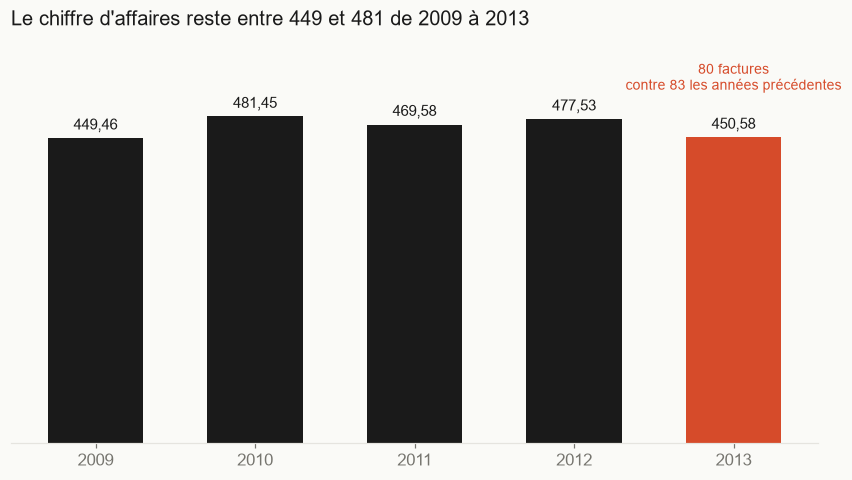

In [5]:
annees = ca_annee["annee"].astype(str)
valeurs = ca_annee["chiffre_affaires"]

fig, ax = plt.subplots(figsize=(8, 4.5))

couleurs = [ACCENT if a == "2013" else INK for a in annees]
barres = ax.bar(annees, valeurs, color=couleurs, width=0.6)

for barre, valeur in zip(barres, valeurs):
    ax.text(
        barre.get_x() + barre.get_width() / 2,
        valeur + 8,
        f"{valeur:.2f}".replace(".", ","),
        ha="center", va="bottom", color=INK, fontsize=10,
    )

# Note sur 2013 (index 4 sur l'axe des catégories)
ax.text(4, 515, "80 factures\ncontre 83 les années précédentes",
        ha="center", va="bottom", color=ACCENT, fontsize=9)

ax.set_ylim(0, 580)
ax.spines["left"].set_visible(False)
ax.tick_params(left=False, labelleft=False)
ax.set_title("Le chiffre d'affaires reste entre 449 et 481 de 2009 à 2013",
             loc="left", fontsize=13, color=INK, pad=16)

fig.tight_layout()
fig.savefig(ROOT / "docs" / "01_ca_par_annee.png", bbox_inches="tight")
plt.show()